<a href="https://colab.research.google.com/github/erikh-1126/03-Project-Group/blob/main/03_tsne_and_umap_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧪 LAB: Non-linear Dimensionality Reduction — t-SNE and UMAP

Over the past few weeks, we have explored how to handle non-linear relationships, mainly in the context of classification and regression tasks.

However, sometimes the first and most important step is to **visualize** the data — to gain intuition, spot structure, or detect outliers — even before any predictive modeling. You have already seen how PCA can help with this, but as we discussed this week, (ordinary) PCA is a linear method and may not capture non-linear patterns in the data effectively.

In this lab, you will learn about two popular **non-linear dimensionality reduction techniques** that are typically used for **data visualization**:  
- **t-SNE (t-distributed Stochastic Neighbor Embedding)**  
- **UMAP (Uniform Manifold Approximation and Projection)**

You will apply and compare these methods on two datasets:
- A simple biological dataset: Palmer Penguins
- A high-dimensional human genotype dataset from the 1000 Genomes Project (adapted from Diaz-Papkovich *et al.*, 2019)

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

---
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


In [10]:
NAME = "Erik Huisman, Derek Wang, Henry You"

## 1. Background Reading (20 points)

Begin by reading **Section 5.3: t-SNE and UMAP for High-Dimensional Data** from the [*Machine Learning Hero* book](https://www.oreilly.com/library/view/machine-learning-hero/9781837025015/), which is available through UVA’s subscription to O’Reilly.

After reading, discuss with your group and respond to the following questions:

a. **Why might we choose t-SNE or UMAP over PCA for dimensionality reduction?**  
Briefly explain the limitations of PCA, and why non-linear methods like t-SNE and UMAP can be more effective in some contexts.

b. **Summarize the strengths and weaknesses of t-SNE and UMAP.**  
What are the key differences between the two methods? In what situations might you prefer one over the other?

c. **What are the main hyperparameters of each method, and what role do they play?**  
Describe how these hyperparameters affect the behavior and output of the algorithms.


**A.** One limitation of PCA is that some of the finer trends or features within the data can go undiscovered while performing PCA, as information in high-variance principal components encodes very slowly, forcing data scientists to use multiple 2D graph projections to look at data. Non-linear methods like t-SNE and UMAP are preferred to PCA when visualizing the finer features because they emphasize the local structure of the data instead.

**B.** t-SNE includes large clusters of points that share common similarities, while also pointing out smaller sub-groups within the cluster for points that share the most commonalities. UMAP attempts to preserve the high-dimension topology of the points by simultaneously establishing connections amongst both neighbor points and long-distant points that still share some sort of connection. Because of its focus on smaller, local connections, t-SNE is really useful when trying to find distinct data clusters. Because of this, however, t-SNE tends to struggle on larger datasets, so UMAP is preferred in those scenarios due its ability to maintain both close connections and global connections.

**C.** The lead hyperparameter for t-SNE is perplexity, which is similar to a nearest neighbors parameter, while the two main hyperparameters for UMAP are the number of local neighbors each point has for manifold approxmation and the minimum distance between points on the projections. Tuning the parameters will make it easier to identify and locate patterns in the data, although increasing the number of neighbors will put more load on your computer and a small minimum distance could break associations between points.

## 2. Experiment with the Palmer Penguins Dataset (Toy Example) (50 points)

To get hands-on experience, you will begin by applying dimensionality reduction techniques to a small and interpretable dataset: Palmer Penguins.

Before you begin coding, read the official documentation for the following methods:

- [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) — from `sklearn.decomposition`
- [t-SNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html) — from `sklearn.manifold`
- [UMAP](https://umap-learn.readthedocs.io/en/latest/basic_usage.html) — from the `umap-learn` package

After reviewing the documentation, complete the following tasks:

a. Load the Palmer Penguins dataset as demonstrated in the [UMAP documentation](https://umap-learn.readthedocs.io/en/latest/basic_usage.html#penguin-data).  

Select the following numerical features:

- `bill_length_mm`  
- `bill_depth_mm`  
- `flipper_length_mm`  
- `body_mass_g`

Then, **standardize** these features so that each has zero mean and unit variance.

In [11]:
# YOUR CODE HERE
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

# Load the penguins dataset
penguins = pd.read_csv("https://raw.githubusercontent.com/allisonhorst/palmerpenguins/c19a904462482430170bfe2c718775ddb7dbb885/inst/extdata/penguins.csv")


penguins = penguins.dropna()
penguins.species.value_counts()

display(penguins.head())
display(penguins["species"].value_counts())

# features standardization
penguin_data = penguins[
    [
        "bill_length_mm",
        "bill_depth_mm",
        "flipper_length_mm",
        "body_mass_g",
    ]
].values

scaled_penguin_data = StandardScaler().fit_transform(penguin_data)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007


,count
species,
Adelie,146
Gentoo,119
Chinstrap,68


b. Apply **PCA**, **t-SNE**, and **UMAP** to reduce the selected features to **2 dimensions**.

Then, for each method:
- Create a **scatter plot** of the 2D projection.
- Use a different color to represent each **species** in the dataset.

This will help you visually assess how well each method separates the species in the reduced space.

*N.B.* You may need to first install `UMAP-learn`. Follow the [documentation](https://umap-learn.readthedocs.io/en/latest/index.html) for that.

In [12]:
# PCA
pca = PCA(n_components=2)
pca_embedding = pca.fit_transform(scaled_penguin_data)

# t-SNE
tsne = TSNE(n_components=2, random_state=42)
tsne_embedding = tsne.fit_transform(scaled_penguin_data)

# UMAP
reducer = umap.UMAP(
    n_components=2,
    random_state=42,
    n_jobs=1
)
umap_embedding = reducer.fit_transform(scaled_penguin_data)

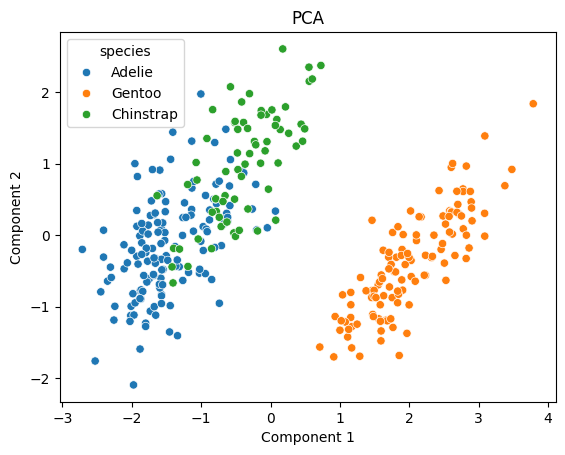

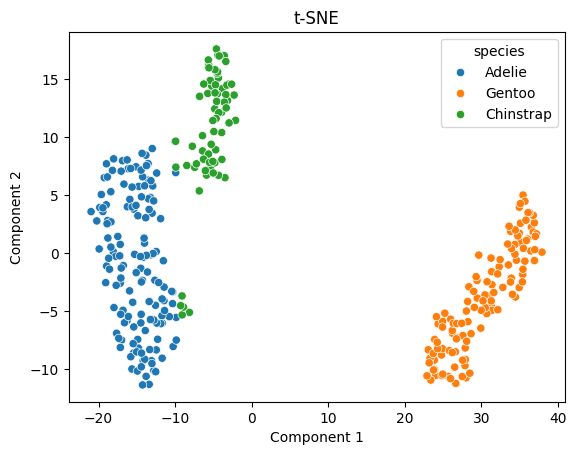

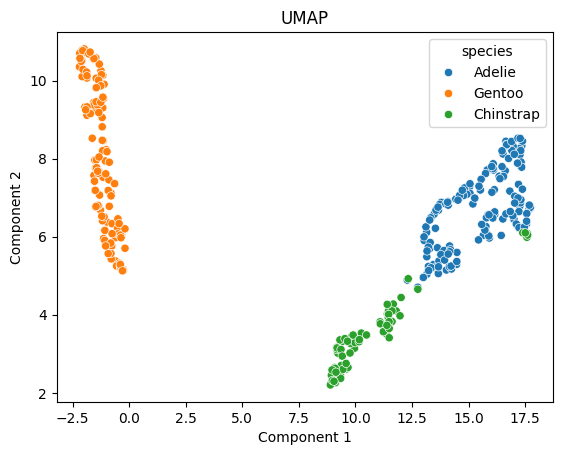

In [13]:
# plotting
results = [pca_embedding, tsne_embedding, umap_embedding]
names = ["PCA", "t-SNE", "UMAP"]

for name, result in zip(names, results):
    plt.figure()

    sns.scatterplot(
        x=result[:, 0],
        y=result[:, 1],
        hue=penguins["species"]
    )

    plt.title(name)
    plt.xlabel("Component 1")
    plt.ylabel("Component 2")
    plt.show()

c. Analyze the resulting plots and describe the main patterns you observe.

- Which method produces the most visually separable clusters?
- Are there any species that overlap in one method but not in others?
- What might explain these differences in how the data is projected?

Elaborate on your observations and compare the strengths and limitations of each method based on this toy example.



Both UMAP and t-SNE produce more visually separable clusters than PCA, and I personally find UMAP to separate them best.

In PCA, Adelie and Chinstrap overlap considerably, with Chinstrap dominating higher component 2 values. In t-SNE, most of the Chinstrap points form a group above Adelie, but a small subset mixes with Adelie. UMAP also separates most Chinstrap points from Adelie, but some overlap remains near the boundaries, and a few green points appear within the lower blue group.

The difference between the cluster separation between PCA, t-SNE, and UMAP could be explained by the approach each take to separate group. PCA finds linear combination of the features that preserve most of the variance, which is not use to separating species. On the other hand, t-SNE and UMAP, focus on neighborhood relationship which allows them to see the structure that is less visible in linear projection.



For this project, PCA could offer a simple projection, but it is not visually friendly. UMAP and t-SNE make the species groups easier to see. However, the nonlinear methods depend on hyperparameters and random initialization. Their cluster spacing, shapes, and sizes should not be interpreted as actual measurements of the dataset.





d. For **t-SNE** and **UMAP**, explore how different hyperparameter settings affect the resulting 2D projections.

- For **t-SNE**, vary the `perplexity` parameter (e.g., 5, 30, 50).
- For **UMAP**, vary the `n_neighbors` parameter (e.g., 5, 15, 50) and optionally `min_dist`.
- Keep `random_state` fixed across all runs so that differences between projections are due primarily to changes in the hyperparameters rather than random initialization.

For each configuration:
- Plot the resulting 2D projection.
- Use color to represent species.

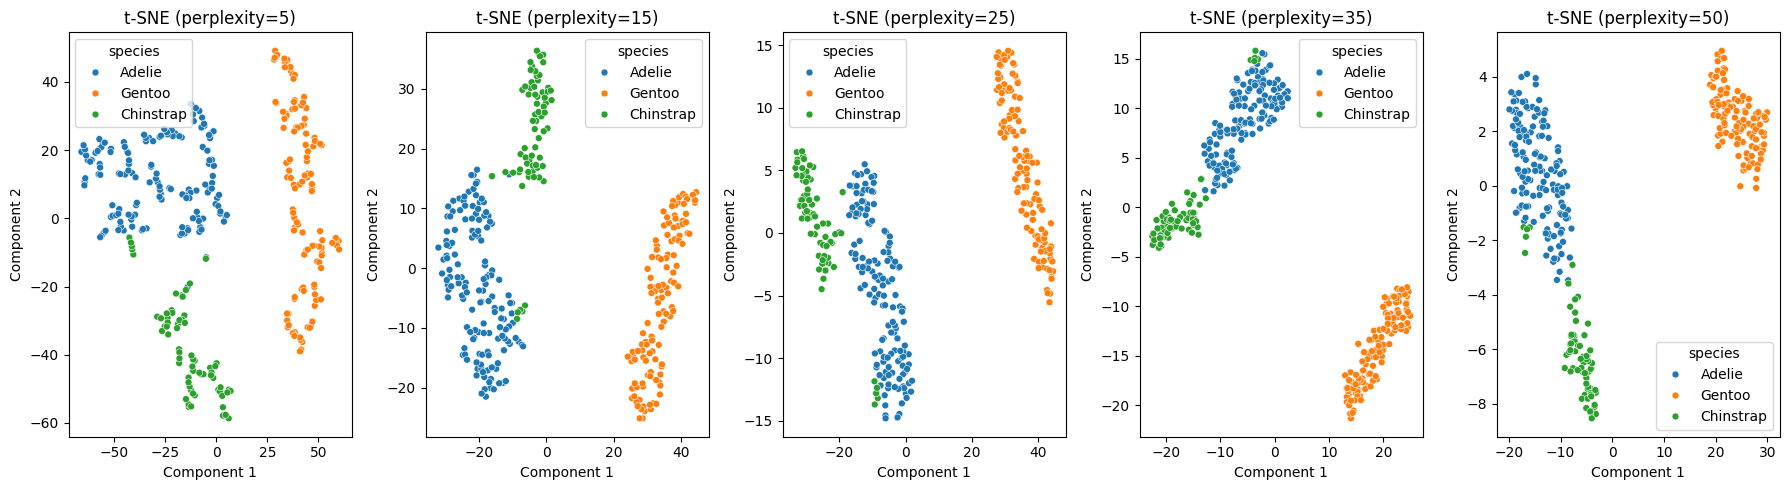

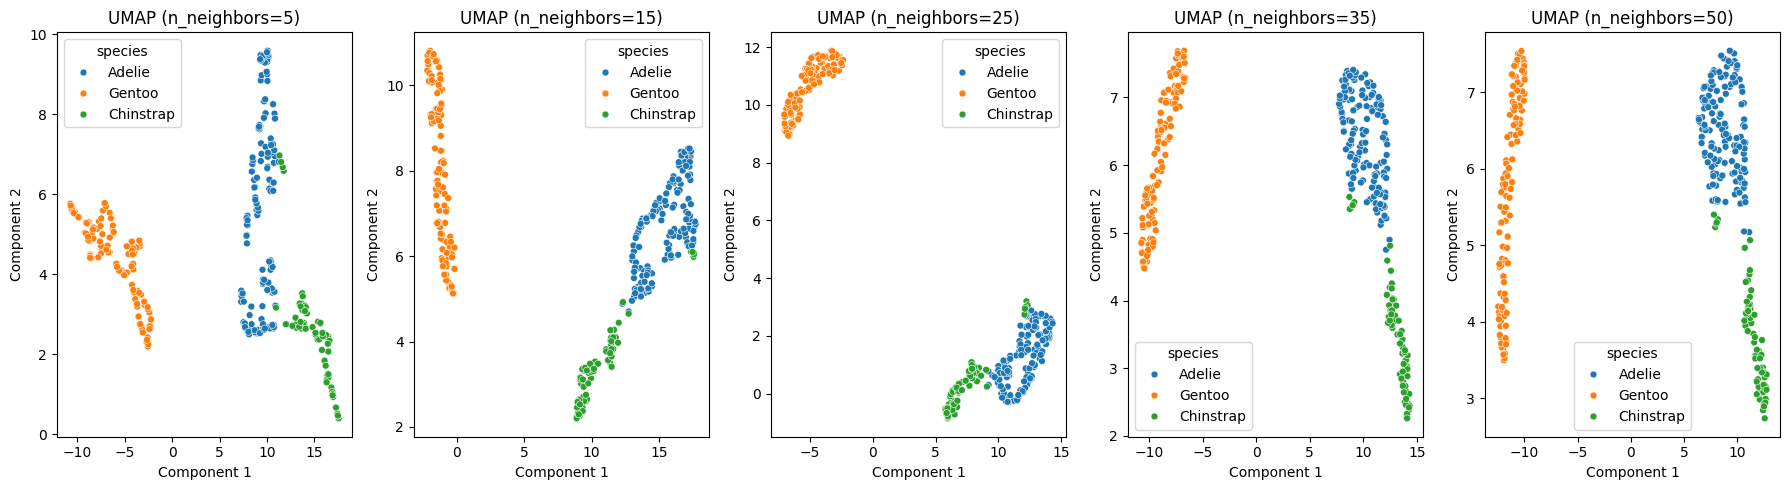

In [14]:
perplexity = [5, 15, 25, 35, 50]
neighbors = [5, 15, 25, 35, 50]

fig, axes = plt.subplots(1, len(perplexity), figsize=(18, 5))
for ax, perp in zip(axes, perplexity):
    emb = TSNE(n_components=2, perplexity=perp, random_state=42).fit_transform(scaled_penguin_data)
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=penguins["species"], ax=ax, s=25)
    ax.set_title(f"t-SNE (perplexity={perp})")
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
plt.tight_layout()
plt.show()

ig, axes = plt.subplots(1, len(neighbors), figsize=(18, 5))
for ax, nn in zip(axes, neighbors):
    emb = umap.UMAP(n_components=2, n_neighbors=nn, random_state=42, n_jobs=1).fit_transform(scaled_penguin_data)
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=penguins["species"], ax=ax, s=25)
    ax.set_title(f"UMAP (n_neighbors={nn})")
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
plt.tight_layout()
plt.show()

After generating the plots, describe the main changes you observe in the visualizations:
- How do the clusters shift, stretch, or separate as hyperparameters change?
- Which settings appear to better preserve the structure of the data?

Elaborate on your observations and support your discussion with specific visual examples.

For t-SNE, a perplexity of 5 has the points mostly spread out across large ranges of the axes, but the points are still in designated groups. As the perplexity goes up to 15-25, the points start to become compact, but the distances between groups are a bit of a concern. If we keep moving up the perplexity to 35 or 50, the Adelie and Chinstrap groups start to become close together and somewhat merge.

For UMAP, having 5 nearest neighbors is similar to a perplexity of 5, where the points are fragmented into smaller chunks. If we increase the nearest neighbors to 15 or 25, the points become really compressed together, with it being hard to tell the boundary between Adelie and Chinstrap. Further increasing the number of nearest neighbors to 35 or 50 is where the boundaries are more clearly defined, while keeping the groups of points compressed.

For both t-SNE and UMAP, a high value of 35 or 50 best maintains the structure of the data that can be seen in part b. The similarities between the Adelie and Chinstrap penguins are distinct in comparison to Gentoo, to the point where both groups are right next to each other but don't blend in. Looking at the graphs in part b, PCA has the two groups basically overlapping, while the other two groups have them more separate, so these higher values of hyperparameters are more representative of a middle-ground between the three graphs.

## 3. Apply to Real Data (1000 Genomes Subset) (25 points)

Your goal in this section is to try to create a figure similar to Figure 1 of the Diaz-Papkovich *et al.* (2019) paper, using a subset of genotype data from the 1000 Genomes Project.

To do so, complete the following steps:

a. Load the genotype dataset accompanying this lab, where each row corresponds to an individual, and each column to a genetic variant. Load also the provided population labels for each individual.

b. **Standardize** the features (i.e., transform the genotype values to have zero mean and unit variance).

c. Apply **PCA**, **t-SNE**, and **UMAP** to reduce the data to 2 dimensions. You may use the default values for the rest of hyperparameters in these techniques.

d. Create **scatter plots** of the resulting projections, coloring each point according to its **population group**.

e. Reflect on the following questions:
- Explain what you observe in each case. Additionally, which method appears to provide the best visual separation of the population into distinct groups? Elaborate on why this might be the case, based on what you know about each method.
- What changes if you first reduce the data to the **top 25 PCA components**, and then apply t-SNE or UMAP?
- In your opinion, what are the trade-offs between **interpretability** (e.g., preservation of local and global structure) and **performance** (e.g., visual separation of known populations and computational time) when using these dimensionality reduction methods?

Please elaborate on your answers and use the plots to support your discussion.

In [15]:
import numpy as np

X = np.load("genome_data_lab3.npy")

labels = np.loadtxt(
    "population_labels_lab3.txt",
    dtype=str
)

In [16]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

X = X.astype(float)
X[X == -1] = np.nan

X_imputed = SimpleImputer(
    strategy="mean"
).fit_transform(X)

X_scaled = StandardScaler().fit_transform(X_imputed)

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import umap

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# PCA
pca_embedding = PCA(
    n_components=2
).fit_transform(X_scaled)

# t-SNE
tsne_embedding = TSNE(
    n_components=2,
    random_state=42,
    init="pca",
    learning_rate="auto"
).fit_transform(X_scaled)

# UMAP
umap_embedding = umap.UMAP(
    n_components=2,
    random_state=42
).fit_transform(X_scaled)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


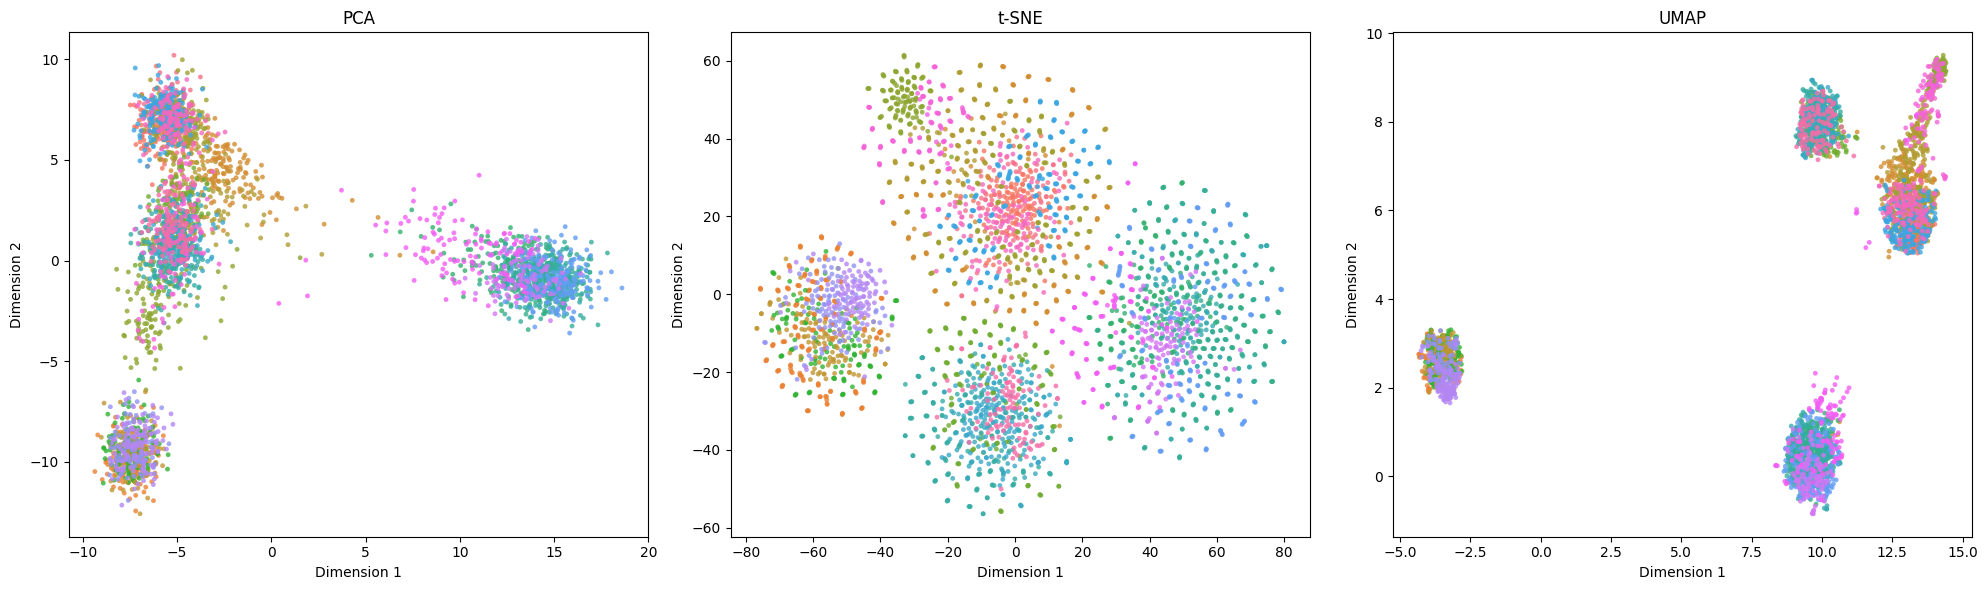

In [18]:
# Plot the three methods
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, embedding, title in zip(
    axes,
    [pca_embedding, tsne_embedding, umap_embedding],
    ["PCA", "t-SNE", "UMAP"]
):
    sns.scatterplot(
        x=embedding[:, 0],
        y=embedding[:, 1],
        hue=labels,
        s=12,
        alpha=0.8,
        linewidth=0,
        legend=False,
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")

plt.tight_layout()
plt.show()

PCA looks very messy. It did not do a good job at distinguishing the populations in the visualization. The t-SNE plot contains large, relatively non-compact clusters. There appears to be some grouping by population. However, the population groups are not completely distinct.  UMAP plot contains four distinct, compact clusters. However, each cluster contains individuals from many different population groups. t-SNE looks like it is the most effective in separating by population group while UMAP has the most distinct groups. This means compact clusters alone do not necessarily indicate better separation of the populations.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


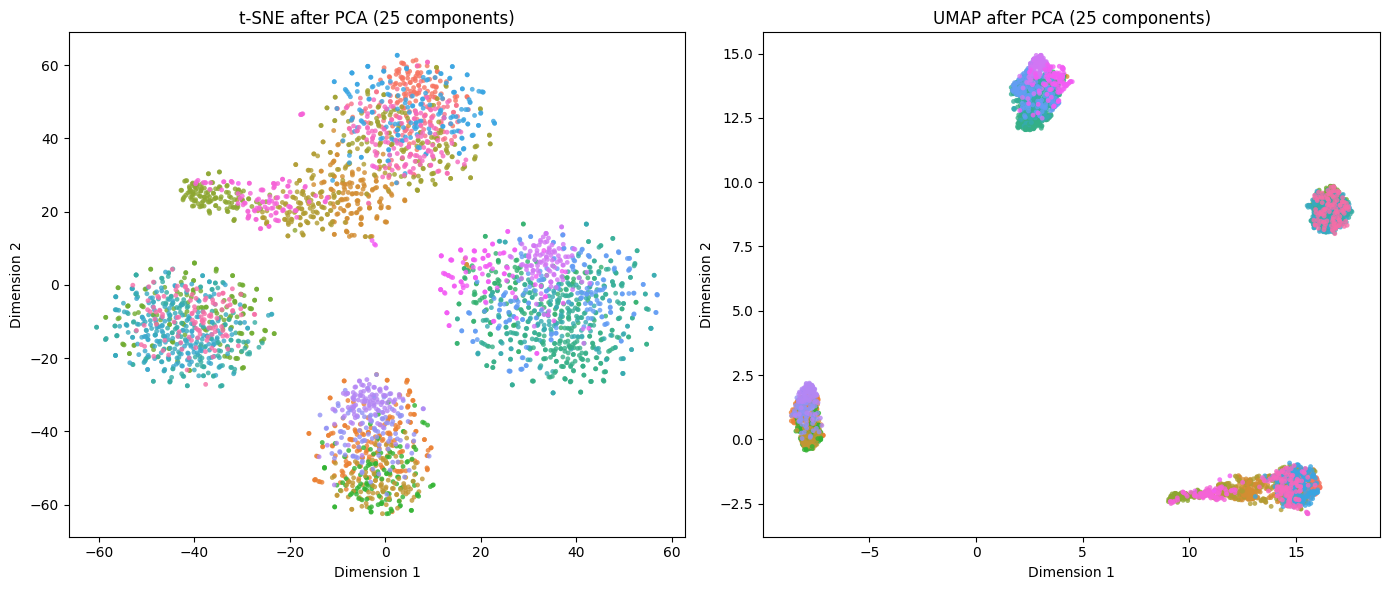

In [19]:
# Reduce to 25 principal components
X_pca25 = PCA(
    n_components=25
).fit_transform(X_scaled)

# t-SNE on PCA-reduced data
tsne_pca_embedding = TSNE(
    n_components=2,
    random_state=42,
    init="pca",
    learning_rate="auto"
).fit_transform(X_pca25)

# UMAP on PCA-reduced data
umap_pca_embedding = umap.UMAP(
    n_components=2,
    random_state=42
).fit_transform(X_pca25)

# Plot the results
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, embedding, title in zip(
    axes,
    [tsne_pca_embedding, umap_pca_embedding],
    ["t-SNE after PCA (25 components)",
     "UMAP after PCA (25 components)"]
):
    sns.scatterplot(
        x=embedding[:, 0],
        y=embedding[:, 1],
        hue=labels,
        s=12,
        alpha=0.8,
        linewidth=0,
        legend=False,
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")

plt.tight_layout()
plt.show()

There is not much change to be honest. t-SNE still shows non-compact clusters with only a little bit of separation by population group. UMAP still shows four distinct groups but with many different population groups.

PCA is the most interpretable because its components capture directions of greatest variation in the original data. However, it may not capture non-linear patterns that distinguish populations.

t-SNE and UMAP focus on preserving local structure. Genetically similar individuals tend to appear near one another. This can reveal population-level patterns, but it may take longer to compute.



## 4. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

One challenge that we had was the combination of our three schedules. As the year is rolling along, midterms are starting to creep up on all of us. This caused our completion of tasks to be pushed back, and we ended up submitting this portion of the lab late at night before the due date due to not being able to find time to complete it in advance. An action that we can take is to be more proactive with our time. Instead of waiting to complete this lab, we should try a little harder to do as much as we can during class or even the couple days following our initial lab date.